# High Frequency Words in 4 Technology Companies 10-K Reports

This notebook answers the seven assignment questions using the main 10-K documents selected for Apple, Amazon, NVIDIA, and Microsoft. All four reports form my single pooled corpus.

The reporting periods differ only because of the filing requirements. Apple ends September 27, 2025, Amazon December 31, 2025, NVIDIA January 25, 2026, Microsoft June 30, 2026. This is a collection of selected top tech companies so it is not a matched period comparison of 10-k yearly filings.


In [5]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib
import json
import re
import time
import unicodedata
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from IPython.display import display, Markdown

DATA = Path('data')
OUTPUT = Path('output')
DATA.mkdir(exist_ok=True)
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False})


# Corpus and sources

I selected these disclosures because financial reporting combines ordinary English with special vocabulary about operations, risk, and accounting. I analyze the entire visible main report, including the headings and table text, but excluding separate exhibits, scripts, styling, and hidden metadata.

Primary sources are linked below. Instead of an API call, 10-k filings are easily searchable with SEC access: https://www.sec.gov/edgar/search/

In [6]:
sources = pd.DataFrame([
    ('Apple', '2025-09-27', 'apple_2025_10k.html',
     'https://www.sec.gov/Archives/edgar/data/320193/000032019325000079/aapl-20250927.htm'),
    ('Amazon', '2025-12-31', 'amazon_2025_10k.html',
     'https://www.sec.gov/Archives/edgar/data/1018724/000101872426000004/amzn-20251231.htm'),
    ('NVIDIA', '2026-01-25', 'nvidia_2026_10k.html',
     'https://www.sec.gov/Archives/edgar/data/1045810/000104581026000021/nvda-20260125.htm'),
    ('Microsoft', '2026-06-30', 'microsoft_2026_10k.html',
     'https://www.sec.gov/Archives/edgar/data/789019/000119312526323660/msft-20260630.htm'),
], columns=['Company', 'Period_end', 'Filename', 'URL'])
display(sources)


,Company,Period_end,Filename,URL
0,Apple,2025-09-27,apple_2025_10k.html,https://www.sec.gov/Archives/edgar/data/320193...
1,Amazon,2025-12-31,amazon_2025_10k.html,https://www.sec.gov/Archives/edgar/data/101872...
2,NVIDIA,2026-01-25,nvidia_2026_10k.html,https://www.sec.gov/Archives/edgar/data/104581...
3,Microsoft,2026-06-30,microsoft_2026_10k.html,https://www.sec.gov/Archives/edgar/data/789019...


In [4]:

SEC_EMAIL = ''

def validate_report(raw, company):
    text = BeautifulSoup(raw, 'html.parser').get_text(' ', strip=True)
    if len(text) < 20000 or '10-k' not in text.lower() or company.lower() not in text.lower():
        raise ValueError(f'{company}: downloaded file does not look like the expected 10-K.')
    if 'your request originates from an undeclared automated tool' in text.lower():
        raise ValueError(f'{company}: SEC block page received.')

raw_reports = {}
provenance = []
errors = []
for row in sources.itertuples(index=False):
    path = DATA / row.Filename
    try:
        origin = 'local cache'
        if path.exists():
            raw = path.read_bytes()
        else:
            if not SEC_EMAIL or '@' not in SEC_EMAIL:
                raise ValueError('Set SEC_EMAIL above, or upload the saved HTML file to data/.')
            response = requests.get(row.URL, headers={
                'User-Agent': f'Academic word frequency project {SEC_EMAIL}'}, timeout=90)
            response.raise_for_status()
            raw = response.content
            validate_report(raw, row.Company)
            path.write_bytes(raw)
            origin = 'downloaded'
            time.sleep(1)
        validate_report(raw, row.Company)
        raw_reports[row.Company] = raw
        provenance.append({'Company': row.Company, 'URL': row.URL,
            'Filename': row.Filename, 'Source': origin,
            'SHA256': hashlib.sha256(raw).hexdigest(),
            'Processed_UTC': datetime.now(timezone.utc).isoformat()})
    except (requests.RequestException, ValueError, OSError) as exc:
        errors.append(f'{row.Company}: {exc}')

if errors:
    raise RuntimeError('All four reports are required. Resolve these issues and rerun:\n'
                       + '\n'.join(errors))
assert len(raw_reports) == 4
pd.DataFrame(provenance).to_csv(OUTPUT / 'source_manifest.csv', index=False)
print('All four reports loaded successfully.')


All four reports loaded successfully.


# Cleaning and defining of a word

A unique word is a distinct lowercase alphabetic token. Hyphens separate words and with a financial filing I chose to have numbers and punctuation excluded. Different forms such as “invest,” “investing,” and “investment” are separate which I think matters with their contextual use. Hidden elements and XBRL headers are removed. Company names, headings, repeated disclosures, and words in tables remain part of this corpus.


In [7]:
def extract_text(raw):
    soup = BeautifulSoup(raw, 'html.parser')
    for tag in list(soup.find_all(True)):
        if tag.parent is None:
            continue
        name = (tag.name or '').lower()
        style = re.sub(r'\s+', '', tag.get('style', '').lower())
        if (name in {'script', 'style', 'noscript', 'head', 'ix:header', 'ix:hidden'}
            or tag.has_attr('hidden')
            or tag.get('aria-hidden', '').lower() == 'true'
            or 'display:none' in style or 'visibility:hidden' in style):
            tag.decompose()
    blocks = {'p', 'div', 'section', 'article', 'table', 'tr', 'td', 'th',
              'li', 'ul', 'ol', 'h1', 'h2', 'h3', 'h4', 'br', 'hr'}
    for tag in soup.find_all(list(blocks)):
        tag.insert_before(' ')
        tag.insert_after(' ')
    text = soup.get_text(separator='')
    text = unicodedata.normalize('NFKC', text).replace('’', "'").replace('‘', "'")
    return re.sub(r'\s+', ' ', text).strip()

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)*", text.lower())

texts = {company: extract_text(raw) for company, raw in raw_reports.items()}
tokens_by_company = {company: tokenize(text) for company, text in texts.items()}
for company, text in texts.items():
    print(f'\n{company}: {len(tokens_by_company[company]):,} tokens')
    print(text[:600])



Apple: 28,103 tokens
UNITED STATES SECURITIES AND EXCHANGE COMMISSION Washington, D.C. 20549 FORM 10-K (Mark One) ☒ ANNUAL REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934 For the fiscal year ended September 27, 2025 or ☐ TRANSITION REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934 For the transition period from to . Commission File Number: 001-36743 Apple Inc. (Exact name of Registrant as specified in its charter) California 94-2404110 (State or other jurisdiction of incorporation or organization) (I.R.S. Employer Identification No.) One Apple Park Way Cupe

Amazon: 39,109 tokens
Table of Contents UNITED STATES SECURITIES AND EXCHANGE COMMISSION Washington, D.C. 20549 ____________________________________ FORM 10-K ____________________________________ (Mark One) ☒ ANNUAL REPORT PURSUANT TO SECTION 13 OR 15(d) OF THE SECURITIES EXCHANGE ACT OF 1934 For the fiscal year ended December 31, 2025 or ☐ TRANSITION REPORT PURSUANT TO SEC

# Unique words in the corpus

Tokens are all word occurrences, types are the distinct words. The pooled vocabulary is a combination so it's not the sum of the companies vocabulary sizes.


In [8]:
tokens = [token for company in sources['Company']
          for token in tokens_by_company[company]]
counts = Counter(tokens)
N = len(tokens)
V = len(counts)
assert N > 0 and V >= 200
summary = pd.DataFrame([
    {'Company': company, 'Total_tokens': len(words), 'Unique_words': len(set(words))}
    for company, words in tokens_by_company.items()
])
summary['Token_share_pct'] = 100 * summary['Total_tokens'] / N
display(summary)
display(Markdown(f'**Answer:** The combined corpus has **{N:,} total word occurrences** '
                 f'and **{V:,} unique words** under the stated definition.'))


,Company,Total_tokens,Unique_words,Token_share_pct
0,Apple,28103,2644,17.547814
1,Amazon,39109,3014,24.420079
2,NVIDIA,48532,3790,30.303901
3,Microsoft,44407,3447,27.728207


**Answer:** The combined corpus has **160,151 total word occurrences** and **5,822 unique words** under the stated definition.

# How many words account for half of all occurrences?

Sort words from highest count to lowest, then take the smallest prefix whose cumulative count reaches at least 50% of all tokens. The 105 most common unique words account for 50.03% of all word occurrences. This is 1.80% of the unique vocabulary.


In [9]:
ranked = pd.DataFrame(sorted(counts.items(), key=lambda pair: (-pair[1], pair[0])),
                      columns=['Word', 'Count'])
ranked.insert(0, 'Rank', np.arange(1, len(ranked) + 1))
ranked['Relative_frequency'] = ranked['Count'] / N
ranked['Frequency_pct'] = 100 * ranked['Relative_frequency']
ranked['Cumulative_count'] = ranked['Count'].cumsum()
ranked['Cumulative_share'] = ranked['Cumulative_count'] / N
k50 = int(np.searchsorted(ranked['Cumulative_count'].to_numpy(), (N + 1) // 2) + 1)
share50 = float(ranked.iloc[k50 - 1]['Cumulative_share'])
assert ranked.iloc[k50 - 1]['Cumulative_count'] >= N / 2
assert k50 == 1 or ranked.iloc[k50 - 2]['Cumulative_count'] < N / 2
display(Markdown(f'**Answer:** The {k50:,} most common unique words account for '
                 f'{share50:.2%} of all word occurrences. '
                 f'This is {k50 / V:.2%} of the unique vocabulary.'))
display(ranked.iloc[max(0, k50 - 3):k50 + 2])


**Answer:** The 105 most common unique words account for 50.03% of all word occurrences. This is 1.80% of the unique vocabulary.

,Rank,Word,Count,Relative_frequency,Frequency_pct,Cumulative_count,Cumulative_share
102,103,primarily,219,0.001367,0.136746,79697,0.497637
103,104,under,218,0.001361,0.136122,79915,0.498998
104,105,all,216,0.001349,0.134873,80131,0.500347
105,106,can,215,0.001342,0.134248,80346,0.501689
106,107,period,211,0.001318,0.131751,80557,0.503007


# The 200 highest frequency words

Relative frequency uses all corpus tokens as the denominator, not only the top 200.


In [10]:
top200 = ranked.head(200).copy()
with pd.option_context('display.max_rows', 200):
    display(top200[['Rank', 'Word', 'Count', 'Frequency_pct', 'Cumulative_share']])
print(f'Top 200 words cover {top200["Relative_frequency"].sum():.2%} of all tokens.')


,Rank,Word,Count,Frequency_pct,Cumulative_share
0,1,and,8519,5.319355,0.053194
1,2,the,6399,3.995604,0.093150
2,3,of,6018,3.757704,0.130727
3,4,to,4278,2.671229,0.157439
4,5,in,3354,2.094274,0.178382
5,6,our,3094,1.931927,0.197701
6,7,or,2209,1.379323,0.211494
7,8,we,1625,1.014667,0.221641
8,9,for,1602,1.000306,0.231644
9,10,a,1595,0.995935,0.241603


Top 200 words cover 59.87% of all tokens.


# Graph of relative frequency

Rank 1 is the most common word and we can see beyond the conjunctions, prepositions, and helping verb words there is a stark drop off. It seems that at about rank 19-22 are the first relative words with frequency of 787, 786, and 762. These words still make up just under half of a percent in word frequency.


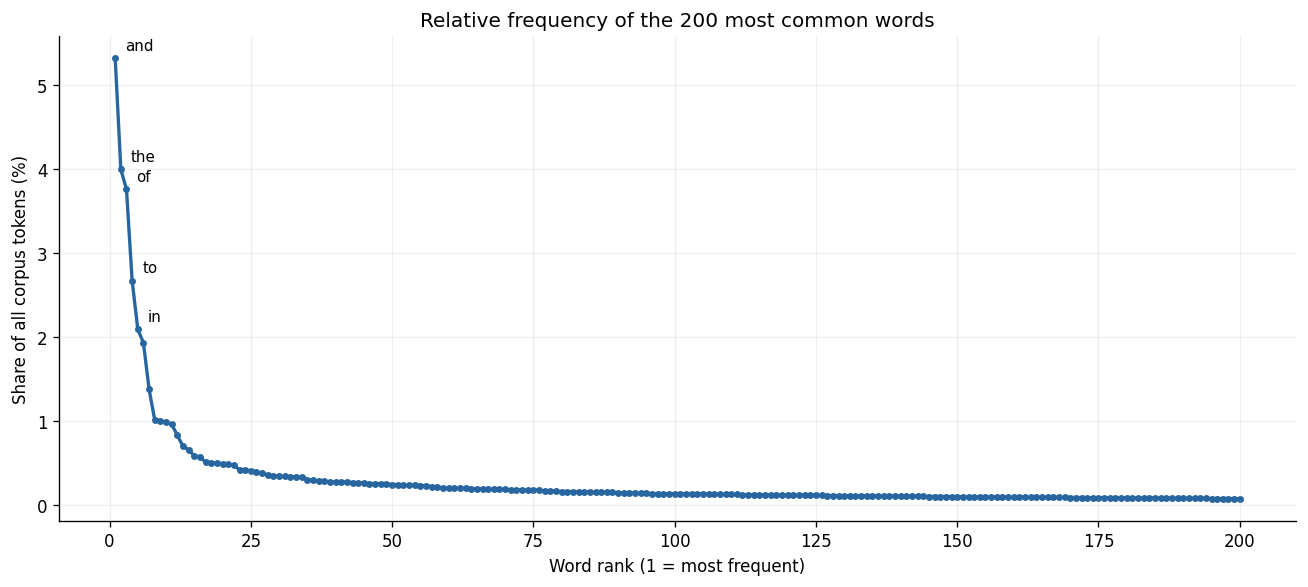

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(top200['Rank'], top200['Frequency_pct'], color='#2866A0', linewidth=2)
ax.scatter(top200['Rank'], top200['Frequency_pct'], s=10, color='#2866A0')
for row in top200.head(5).itertuples(index=False):
    ax.annotate(row.Word, (row.Rank, row.Frequency_pct),
                xytext=(6, 5), textcoords='offset points', fontsize=9)
ax.set(xlabel='Word rank (1 = most frequent)', ylabel='Share of all corpus tokens (%)',
       title='Relative frequency of the 200 most common words')
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUTPUT / 'top_200_relative_frequency.png', dpi=200)
plt.show()


# Does the distribution follow Zipf’s law?

Zipf’s law predicts about $f(r)=C/r$, where r is rank. On log–log axes this has slope −1. I compare the top 200 observed frequencies with a reference line with intercept chosen to minimize squared log residuals while its slope is fixed at −1. A separate least squares fit estimates the slope freely so the reference line is a visual benchmark.

A high log-scale R^2 alone does not establish Zipf’s law. The top 200 words follow an approximately power law rank frequency pattern with an estimated exponent of 0.822. This resembles Zipf’s law but frequencies decline more slowly than the classic version that assumes an exponent of 1. The descriptive  R^2 of 0.994 absolutely suggests a close fit to a straight line, but does not demonstrate the exact Zipf relationship. I therefore describe this corpus as showing a Zipf like rank frequency pattern but has clear deviation from the strict law. This analysis does not establish whether this relationship holds across the entire vocabulary.


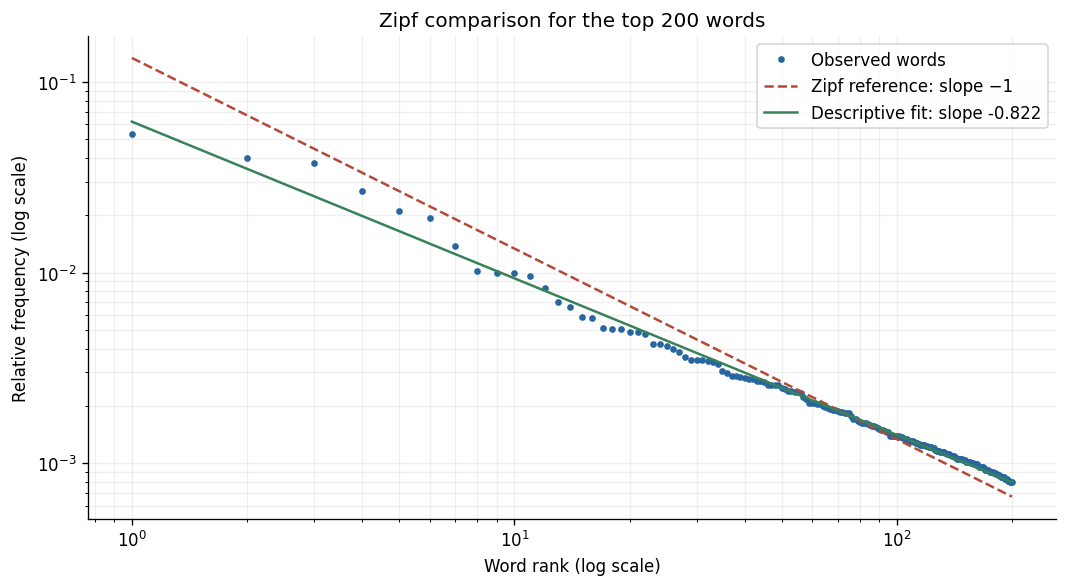

The fitted log–log slope is **-0.822**, compared with Zipf’s predicted **−1**. Log-scale R² is **0.994**. Inspect whether the observed points follow the reference line or show systematic curvature before writing the final interpretation.

In [12]:
ranks = top200['Rank'].to_numpy(dtype=float)
freqs = top200['Relative_frequency'].to_numpy()
x, y = np.log10(ranks), np.log10(freqs)
slope, intercept = np.polyfit(x, y, 1)
fitted = 10 ** (intercept + slope * x)
zipf_intercept = np.mean(y + x)
zipf_reference = 10 ** zipf_intercept / ranks
r2 = 1 - np.sum((y - (intercept + slope * x)) ** 2) / np.sum((y - y.mean()) ** 2)
fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(ranks, freqs, 'o', markersize=3, label='Observed words', color='#2866A0')
ax.loglog(ranks, zipf_reference, '--', color='#B34A36', label='Zipf reference: slope −1')
ax.loglog(ranks, fitted, color='#38825A', label=f'Descriptive fit: slope {slope:.3f}')
ax.set(xlabel='Word rank (log scale)', ylabel='Relative frequency (log scale)',
       title='Zipf comparison for the top 200 words')
ax.legend()
ax.grid(alpha=.2, which='both')
fig.tight_layout()
fig.savefig(OUTPUT / 'zipf_comparison.png', dpi=200)
plt.show()
display(Markdown(f'The fitted log–log slope is **{slope:.3f}**, compared with Zipf’s '
                 f'predicted **−1**. Log-scale R² is **{r2:.3f}**. '
                 'Inspect whether the observed points follow the reference line or show '
                 'systematic curvature before writing the final interpretation.'))




#How does this differ from all words in all corpora?

These reports address investors and regulators so business, accounting, and risk vocabulary should be more common than in everyday conversation or writing. Company names and specialized product terms related to tech might also appear more than normal. Common grammatically useful words are still expected to dominate many high ranks because they connect subjects and actions in sentences.

The four large tech companies reporting periods are not identical which could be something to consider how language is used in a final year report. There really can't be a single universal “all corpora” distribution since the comparison depends on which languages and genres are included but we assume ours for the general english language. These differences are plausible explanations, not measured differences against a reference corpus. For example words like “financial” ranks 21st, “tax” ranks 24th, and “income” ranks 25th in this corpus. Those are very high positions which emphasize the reporting focus.


